# NVIDIA BioClip2 — Crop Analysis

Runs **NVIDIA BioClip2** on every background-removed crop in `crops_nobg_matting`.

### Steps
1. Check GPU
2. Mount Google Drive
3. Install dependencies
4. Configure paths
5. Load BioClip2 model
6. Load crops
7. Zero-shot species classification
8. Embed all crops
9. HDBSCAN clustering
10. Visualize cluster grid
11. Save results to CSV

## 1 · Check GPU
Make sure you're on a GPU runtime: Runtime → Change runtime type → GPU.

In [1]:
!nvidia-smi

Mon May 18 21:25:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P0             44W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2 · Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3 · Install Dependencies

In [3]:
!pip install -q open_clip_torch scikit-learn umap-learn dropbox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.3/162.3 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 6.6 MB/s eta 0:00:00


## 4 · Configure Paths

Set `MISSION_CSV` to the mission-57 bounding-box CSV and `VIDEOS_DIR` to the folder containing the source `.mp4` files.

In [ ]:
import os

DRIVE_ROOT  = '/content/drive/My Drive'

# ── Dropbox credentials ───────────────────────────────────────────────────────
DROPBOX_TOKEN     = 'sl.u.AGeuFQjMj6rPVrmmvKjUqcYu_JMcBBD2ZVcH2rNS_R7gKwlCfa_Hku-tNI6jLWGtKwQ-k6CZU5odNSKvWt7IKLAv2cpX9J482J8jjpMnJuHqV3cAP0nUxYRs54Jm2gcqnUkdC7Adpu2ttqVPTgnVqrXE6J77r_nkNmxJ2n0ioo30k-y4IOgQuDlI0yRSUSRz3XaHAS8B-9odXmYFCBqWdylDgQRdZeGUVaScL2Ni5HLQtOOvl2fhpaQKz08KuH6M8ZKyIqfnHMa4HhILzNgEhhnnJGBQYohPgUAhSRJUoU43_8FcIyrMDf0syM-WwF0MhqE6RhiehcR7oQw4asMYIeGpdtukWsR__-NVcGX-zbKOvPY875OpVCvNMNHczrf9V7JuJXAKa3ilN-SRmE_hnTqBPSirMeHLyTAV8S1jIKuIMXP0VlCSqLkXaV_LHGf9u8uOiCF26hzOvYmh1sYxbH75ypCvsErMAeG52k8S6wASgxDvF83yjlnFPluWQ2WuLYqyVOD0p2KTKMSR36tjbc8H817FklKPo7K_jjW6l_gfOeN3WTUl3pVwP3tAxgKugHwlYOiqARUvSLx2izHJc3sXsF9jT5QqvvKjYY2iAY8RxsgfGKykJ4f71CeOcXn_yA9JXiybCTgXxiKViPAk7reE4XH67lMvSEaj2T2xEFLyN2_xaEbwCj6EbHGZ6FZGT-4wKf7nah1-L9eCCKTUW5y-iTTJ_0OpqeJNG9-Iv1uNRkKwWz_SxHFgJQEUncxv5kTlqKP1B2CXftCSMi2x47GLDLpiiwm016ZDIdcHegZQ2Y2gWFFMvw5XmsqkAEE8snNcWNbJAHsZ66j9meviCfk-CoWbbjXVlts5XSbGe6v7_OVPbNWD0VTypdnXkSUTX8y06KF9TPFz9Mt_Eg_GIeVFaZBMs2yveuoHDhKaQ2kUPG1H4qcf7nBDcJV04AWjphG5iCSfSROuciMCX52eNb4EKkJg1Th7sjmx1Jzqy0JbcFLsS3LiLDzn4EFeRgtRCdW4Oo_eFphOQ781u8-mrIIqcFE8saxNhiqJoE8hu8gtBG5cJuuwfZ7C8GusrzeSmFl3X2XeRk1mY9Fx-GwsT84VLtWm4b5wY0OwCWL3iBpmx6z5IO5put0IcEZeDPnr9Z4HsMEBJ6Ww4UrWFHK2xlwmzk0wqE_v7Kr00gZ7Vm9coxZFe17phmIEmf9impi7yG7Fl0aAboVQFA_P7xcXteavf0wmDN69IFB7ggg2ZCfGzokpz_NqpYDmKuKbsCfH4h8fOLR8JfuRcu5dLM34wmD09fwixm3TEBNkrupTUkjtmTaJ-aqouiUoWrAb6o_vCTBXRH7KyNf4y2o8WvgsHZQ31ZWeNFFf21te-62KgbQkkFpuZdrbKVWfSYAbpsM23C_GHvcbFd_CLvyGuqK11fiFO5wJEQ7XfpFuJu7k5DSQdw'
# paste your Dropbox access token
DROPBOX_BASE_PATH = '/DOEX0096_Palau'       # root folder in Dropbox

# ── Input: mission-57 bounding-box CSV (on Google Drive) ─────────────────────
MISSION_CSV = os.path.join(DRIVE_ROOT, 'mission_57.csv')

# ── Output: CSV with embeddings, species predictions, and cluster IDs ─────────
OUTPUT_DIR  = os.path.join(DRIVE_ROOT, 'output')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── BioClip2 inference settings ───────────────────────────────────────────────
BATCH_SIZE        = 32    # images per forward pass; lower if you hit OOM
TOP_K             = 20     # how many top species predictions to report
MIN_CLUSTER_SIZE  = 5     # HDBSCAN minimum cluster size

# ── Zero-shot candidate labels ────────────────────────────────────────────────
CANDIDATE_LABELS = [
    'fish', 'reef fish', 'tropical fish', 'shark', 'ray', 'manta ray',
    'stingray', 'jellyfish', 'octopus', 'squid', 'cuttlefish', 'crab',
    'lobster', 'shrimp', 'sea turtle', 'eel', 'moray eel', 'starfish',
    'sea urchin', 'coral', 'sea anemone', 'nudibranch', 'seahorse',
    'clownfish', 'parrotfish', 'grouper', 'tuna', 'barracuda',
]

print('Config OK')
print(f'Mission CSV: {MISSION_CSV}')
print(f'Output dir : {OUTPUT_DIR}')

Config OK
Mission CSV: /content/drive/My Drive/mission_57.csv
Output dir : /content/drive/My Drive/output


## 4b · Connect to Dropbox

In [5]:
import dropbox

dbx = dropbox.Dropbox(DROPBOX_TOKEN)

try:
    dbx.users_get_current_account()
    print('Dropbox connection OK')
    
    for entry in dbx.files_list_folder('/DOEX0096_Palau').entries:
        print(entry.name)
  
except dropbox.exceptions.AuthError:
    raise RuntimeError('Dropbox auth failed — check your DROPBOX_TOKEN.')

Dropbox connection OK
PLW_dscm_01
PLW_dscm_02
PLW_dscm_03
PLW_dscm_04
PLW_dscm_05
PLW_dscm_06
PLW_dscm_07
PLW_dscm_08
PLW_dscm_32
PLW_dscm_33
PLW_dscm_34
PLW_dscm_09
PLW_dscm_35
PLW_dscm_10
PLW_dscm_11
PLW_dscm_12
PLW_dscm_13
PLW_dscm_14
PLW_dscm_15
PLW_dscm_16
PLW_dscm_17
PLW_dscm_18
PLW_dscm_19
PLW_dscm_20
PLW_dscm_21
PLW_dscm_22
PLW_dscm_23
PLW_dscm_24
PLW_dscm_25
PLW_dscm_26
PLW_dscm_27
PLW_dscm_28
PLW_dscm_29
PLW_dscm_30
PLW_dscm_31
PLW_dscm_36
PLW_dscm_37
PLW_dscm_38
PLW_dscm_39
PLW_dscm_40
PLW_dscm_41
PLW_dscm_42
PLW_dscm_43
PLW_dscm_44
PLW_dscm_45
PLW_dscm_46
PLW_dscm_47
PLW_dscm_48
PLW_dscm_49
PLW_dscm_50
PLW_dscm_51
PLW_dscm_52
PLW_dscm_53
PLW_dscm_54
PLW_dscm_55
PLW_dscm_57
PLW_dscm_58
PLW_dscm_56
PLW_2024_dscm_fieldbook.xlsx


## 5 · Load NVIDIA BioClip2

In [6]:
import open_clip
import torch

BIOCLIP_MODEL = 'hf-hub:imageomics/bioclip'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')

model, preprocess_train, preprocess_val = open_clip.create_model_and_transforms(BIOCLIP_MODEL)
tokenizer = open_clip.get_tokenizer(BIOCLIP_MODEL)
model = model.to(device).eval()

print(f'BioCLIP loaded: {BIOCLIP_MODEL}')

Device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:103: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

BioCLIP loaded: hf-hub:imageomics/bioclip


## 6 · Extract Crops from Mission-57 Videos

Reads `mission_57.csv`, selects the highest-confidence detection per track,
seeks to that frame in the source video, and crops the bounding box region.

**Checkpointing:** crops are saved as PNGs to `crop_checkpoints/` on Drive in
batches of 30 tracks. Re-running this cell skips already-completed tracks so
you can safely pause and resume across Colab sessions.

In [ ]:
import os
import tempfile
import urllib.request
import cv2
import pandas as pd
from PIL import Image

CROP_BATCH_SIZE = 30   # tracks per batch before saving to Drive
CHECKPOINT_DIR  = os.path.join(OUTPUT_DIR, 'crop_checkpoints')
CHECKPOINT_META = os.path.join(CHECKPOINT_DIR, 'crop_meta.csv')
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ── Load bounding-box CSV ─────────────────────────────────────────────────────
bbox_df = pd.read_csv(MISSION_CSV)
print(f'Loaded {len(bbox_df):,} detections across {bbox_df["media_id"].nunique()} video(s)')

# ── Per track: keep only the highest-confidence detection ─────────────────────
best = (
    bbox_df
    .sort_values('confidence', ascending=False)
    .drop_duplicates(subset=['media_id', 'track_id'])
    .reset_index(drop=True)
)
print(f'Unique tracks: {len(best)}')

# ── Resume: find already-completed tracks ─────────────────────────────────────
if os.path.exists(CHECKPOINT_META):
    done_df   = pd.read_csv(CHECKPOINT_META)
    done_keys = set(zip(done_df['media_id'], done_df['track_id'].astype(int)))
    print(f'Resuming — {len(done_keys)} tracks already saved to Drive')
else:
    done_keys = set()

remaining = best[
    ~best.apply(lambda r: (r['media_id'], int(r['track_id'])) in done_keys, axis=1)
].reset_index(drop=True)
print(f'Tracks remaining: {len(remaining)}')

# ── Local video cache ─────────────────────────────────────────────────────────
VIDEO_CACHE = tempfile.mkdtemp(prefix='bioclip_videos_')


def deployment_from_media_id(media_id):
    """'PLW_dscm_57_c002.mp4' → 'PLW_dscm_57'."""
    stem  = os.path.splitext(media_id)[0]
    parts = stem.rsplit('_', 1)
    if len(parts) == 2 and parts[1].startswith('c') and parts[1][1:].isdigit():
        return parts[0]
    return stem


def fetch_video(video_name):
    local_path = os.path.join(VIDEO_CACHE, video_name)
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        return local_path
    deployment   = deployment_from_media_id(video_name)
    dropbox_path = f'{DROPBOX_BASE_PATH}/{deployment}/Video/{video_name}'
    try:
        link = dbx.files_get_temporary_link(dropbox_path)
        urllib.request.urlretrieve(link.link, local_path)
        return local_path
    except Exception as e:
        print(f'  WARNING: could not fetch {dropbox_path}: {e}')
        return None


def save_checkpoint(new_rows):
    """Append new metadata rows to the Drive checkpoint CSV."""
    new_df = pd.DataFrame(new_rows)
    if os.path.exists(CHECKPOINT_META):
        new_df.to_csv(CHECKPOINT_META, mode='a', header=False, index=False)
    else:
        new_df.to_csv(CHECKPOINT_META, index=False)


# ── Process in batches of CROP_BATCH_SIZE tracks ─────────────────────────────
total_batches = max(1, (len(remaining) + CROP_BATCH_SIZE - 1) // CROP_BATCH_SIZE)

for batch_idx in range(total_batches):
    batch = remaining.iloc[batch_idx * CROP_BATCH_SIZE : (batch_idx + 1) * CROP_BATCH_SIZE]
    print(f'\nBatch {batch_idx + 1}/{total_batches}  ({len(batch)} tracks)', flush=True)

    new_rows  = []
    open_caps = {}   # video_name → cv2.VideoCapture (or None if unavailable)

    for _, row in batch.iterrows():
        video_name = row['media_id']

        if video_name not in open_caps:
            local_path = fetch_video(video_name)
            if local_path is None:
                open_caps[video_name] = None
            else:
                cap = cv2.VideoCapture(local_path)
                open_caps[video_name] = cap if cap.isOpened() else None

        cap = open_caps[video_name]
        if cap is None:
            continue

        vid_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        vid_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(row['frame']))
        ret, frame_bgr = cap.read()
        if not ret:
            continue

        x1 = max(0,     int(row['x']                  * vid_w))
        y1 = max(0,     int(row['y']                  * vid_h))
        x2 = min(vid_w, int((row['x'] + row['width']) * vid_w))
        y2 = min(vid_h, int((row['y'] + row['height']) * vid_h))
        if x2 <= x1 or y2 <= y1:
            continue

        crop_rgb  = cv2.cvtColor(frame_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
        track_id  = int(row['track_id'])
        crop_name = f'{os.path.splitext(video_name)[0]}__id{track_id:06d}.png'
        Image.fromarray(crop_rgb).save(os.path.join(CHECKPOINT_DIR, crop_name))

        new_rows.append({
            'media_id'  : video_name,
            'track_id'  : track_id,
            'frame'     : int(row['frame']),
            'confidence': float(row['confidence']),
            'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
            'crop_file' : crop_name,
        })

    for cap in open_caps.values():
        if cap is not None:
            cap.release()

    if new_rows:
        save_checkpoint(new_rows)
        total_done = len(done_keys) + (batch_idx + 1) * CROP_BATCH_SIZE
        print(f'  Checkpoint saved — {len(new_rows)} crops written  '
              f'(~{min(total_done, len(best))}/{len(best)} total)')

print(f'\nAll batches complete.')

# ── Load all saved crops into memory ─────────────────────────────────────────
crop_meta_df = pd.read_csv(CHECKPOINT_META)
pil_images, crop_meta = [], []

for _, row in crop_meta_df.iterrows():
    crop_path = os.path.join(CHECKPOINT_DIR, row['crop_file'])
    if os.path.exists(crop_path):
        pil_images.append(Image.open(crop_path).convert('RGB'))
        crop_meta.append(row.to_dict())

print(f'Loaded {len(pil_images)} crops into memory')
if not pil_images:
    raise RuntimeError('No crops loaded. Check CHECKPOINT_DIR and crop PNG files.')

## 6b · Background Removal with BiRefNet

Runs **BiRefNet** on every extracted crop to isolate the animal from its background.
The resulting RGBA images (alpha = foreground mask) replace `pil_images` so all
downstream cells (embedding, clustering, visualisation) operate on clean subjects.

In [27]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rembg[gpu]"], check=True)

import numpy as np
import cv2
from PIL import Image
from rembg import remove, new_session

# BiRefNet — best quality for fine animal edges; falls back to u2net on CPU
try:
    session = new_session("birefnet-general")
    print('Using BiRefNet session')
except Exception:
    session = new_session("u2net")
    print('Fell back to u2net session')

def remove_background(pil_img: Image.Image) -> Image.Image:
    """Remove background with rembg/BiRefNet, feather the edge, return RGBA."""
    result_rgba = remove(pil_img.convert('RGB'), session=session)

    w_crop, h_crop = pil_img.size

    alpha_raw = np.array(result_rgba)[:, :, 3]
    alpha_mask = cv2.resize(
        alpha_raw.astype(np.float32),
        (w_crop, h_crop),
        interpolation=cv2.INTER_LANCZOS4,
    )
    alpha_mask = np.clip(alpha_mask, 0, 255).astype(np.uint8)

    # Feather edge
    alpha_f    = cv2.GaussianBlur(alpha_mask.astype(np.float32), (3, 3), sigmaX=0.8)
    alpha_mask = np.clip(alpha_f, 0, 255).astype(np.uint8)

    rgba = pil_img.convert('RGBA')
    rgba.putalpha(Image.fromarray(alpha_mask))
    return rgba

# ── Run on all crops ──────────────────────────────────────────────────────────
pil_images_nobg = []
skipped = 0

for i, img in enumerate(pil_images):
    try:
        pil_images_nobg.append(remove_background(img))
    except Exception as e:
        print(f'  WARNING: crop {i} failed ({e}), keeping original')
        pil_images_nobg.append(img.convert('RGBA'))
        skipped += 1

    if (i + 1) % 10 == 0 or (i + 1) == len(pil_images):
        print(f'  BiRefNet: {i + 1}/{len(pil_images)}', end='\r')

print(f'\nDone — {len(pil_images_nobg)} crops processed, {skipped} skipped')

# Replace so downstream cells use the cleaned crops
pil_images = pil_images_nobg

  0%|                                               | 0.00/973M [00:00<?, ?B/s]

Using BiRefNet session
  BiRefNet: 663/663
Done — 663 crops processed, 0 skipped


## 7 · Zero-Shot Species Classification

BioClip2 is a CLIP-style model, so we can compare image embeddings against
text embeddings of candidate species labels to get zero-shot predictions.

In [28]:
import numpy as np

# ── Encode text labels once ───────────────────────────────────────────────────
prompts = [f'a photo of a {label}' for label in CANDIDATE_LABELS]
text_tokens = tokenizer(prompts).to(device)

with torch.no_grad():
    text_features = model.encode_text(text_tokens)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

print(f'Text features: {text_features.shape}  ({len(CANDIDATE_LABELS)} labels)')

# ── Encode images in batches, compute cosine similarity ──────────────────────
all_image_features = []
all_probs          = []

for start in range(0, len(pil_images), BATCH_SIZE):
    batch   = pil_images[start : start + BATCH_SIZE]
    tensors = torch.stack([preprocess_val(img) for img in batch]).to(device)

    with torch.no_grad():
        img_feats = model.encode_image(tensors)
        img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)

    logit_scale = model.logit_scale.exp()
    logits      = logit_scale * img_feats @ text_features.T
    probs       = logits.softmax(dim=-1).detach().cpu().float().numpy()

    all_image_features.append(img_feats.cpu().float().numpy())
    all_probs.append(probs)

    end = min(start + BATCH_SIZE, len(pil_images))
    print(f'  Processed {end}/{len(pil_images)}', end='\r')

image_embeddings = np.vstack(all_image_features)
all_probs        = np.vstack(all_probs)

print(f'\nEmbedding matrix : {image_embeddings.shape}')
print(f'Probability matrix: {all_probs.shape}')

Text features: torch.Size([28, 512])  (28 labels)
  Processed 663/663
Embedding matrix : (663, 512)
Probability matrix: (663, 28)


In [30]:
import pandas as pd
from IPython.display import display

# ── Build per-crop predictions table ─────────────────────────────────────────
records = []
for i, meta in enumerate(crop_meta):
    top_k_idx  = all_probs[i].argsort()[::-1][:TOP_K]
    top_labels = [CANDIDATE_LABELS[j] for j in top_k_idx]
    top_scores = [float(all_probs[i][j]) for j in top_k_idx]

    rec = {
        'media_id'   : meta['media_id'],
        'track_id'   : meta['track_id'],
        'frame'      : meta['frame'],
        'confidence' : meta['confidence'],
        'top1_label' : top_labels[0],
        'top1_score' : round(top_scores[0], 4),
    }
    for rank, (lbl, score) in enumerate(zip(top_labels, top_scores), start=1):
        rec[f'top{rank}_label'] = lbl
        rec[f'top{rank}_score'] = round(score, 4)
    records.append(rec)

predictions_df = pd.DataFrame(records)
print(f'Predictions for {len(predictions_df)} crops')
display(predictions_df.head(20))

print('\nTop-1 label distribution:')
print(predictions_df['top1_label'].value_counts().to_string())

Predictions for 663 crops


,media_id,track_id,frame,confidence,top1_label,top1_score,top2_label,top2_score,top3_label,top3_score,...,top16_label,top16_score,top17_label,top17_score,top18_label,top18_score,top19_label,top19_score,top20_label,top20_score
0,PLW_dscm_57_c002.mp4,5,593,0.6826,shark,0.9365,stingray,0.0294,jellyfish,0.0177,...,barracuda,0.0000,manta ray,0.0000,lobster,0.0000,crab,0.0000,tuna,0.0000
1,PLW_dscm_57_c002.mp4,9,612,0.8141,shark,0.8465,manta ray,0.0374,coral,0.0290,...,crab,0.0002,starfish,0.0002,clownfish,0.0001,shrimp,0.0001,sea urchin,0.0001
2,PLW_dscm_57_c002.mp4,86,732,0.7315,eel,0.7954,squid,0.1073,shark,0.0481,...,reef fish,0.0001,jellyfish,0.0001,nudibranch,0.0001,crab,0.0000,starfish,0.0000
3,PLW_dscm_57_c002.mp4,89,748,0.8289,fish,0.4948,shark,0.4650,seahorse,0.0147,...,shrimp,0.0000,reef fish,0.0000,cuttlefish,0.0000,sea anemone,0.0000,nudibranch,0.0000
4,PLW_dscm_57_c008.mp4,189,162,0.6332,stingray,0.6222,shark,0.2837,squid,0.0671,...,moray eel,0.0000,sea anemone,0.0000,lobster,0.0000,reef fish,0.0000,crab,0.0000
5,PLW_dscm_57_c008.mp4,192,565,0.5991,manta ray,0.8489,shark,0.0808,squid,0.0635,...,octopus,0.0000,stingray,0.0000,nudibranch,0.0000,tropical fish,0.0000,moray eel,0.0000
6,PLW_dscm_57_c009.mp4,199,74,0.4274,shark,0.5033,crab,0.1864,seahorse,0.0653,...,nudibranch,0.0020,tropical fish,0.0017,ray,0.0005,coral,0.0004,clownfish,0.0002
7,PLW_dscm_57_c009.mp4,200,177,0.5913,shark,0.6271,stingray,0.2659,ray,0.0408,...,seahorse,0.0001,tropical fish,0.0000,grouper,0.0000,coral,0.0000,clownfish,0.0000
8,PLW_dscm_57_c009.mp4,205,273,0.7575,fish,0.9940,shark,0.0045,eel,0.0008,...,sea anemone,0.0000,reef fish,0.0000,shrimp,0.0000,cuttlefish,0.0000,sea urchin,0.0000
9,PLW_dscm_57_c009.mp4,206,287,0.4490,shark,0.8524,fish,0.0646,eel,0.0305,...,sea anemone,0.0001,shrimp,0.0000,sea turtle,0.0000,reef fish,0.0000,sea urchin,0.0000



Top-1 label distribution:
top1_label
shark            255
stingray          72
squid             59
ray               50
eel               43
fish              40
manta ray         24
barracuda         21
seahorse          20
coral             18
sea turtle        12
jellyfish         10
lobster            8
crab               8
tropical fish      7
clownfish          6
nudibranch         6
starfish           2
octopus            2


## 8 · UMAP Projection (optional visualisation)

Project the high-dimensional BioClip2 embeddings to 2-D for a scatter plot
coloured by the top-1 predicted species.

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


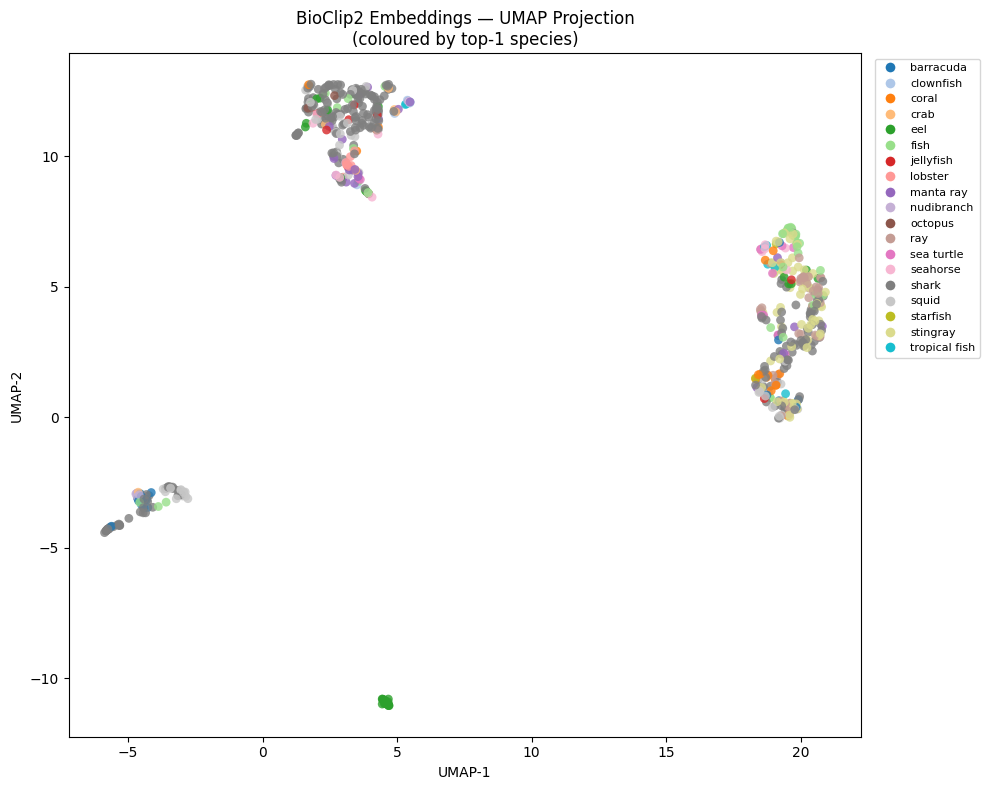

In [31]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

try:
    import umap
    reducer  = umap.UMAP(n_components=2, random_state=42, n_neighbors=min(15, len(image_embeddings)-1))
    coords_2d = reducer.fit_transform(image_embeddings)

    unique_labels = sorted(predictions_df['top1_label'].unique())
    color_map     = {lbl: cm.tab20(i / len(unique_labels)) for i, lbl in enumerate(unique_labels)}
    colors        = [color_map[lbl] for lbl in predictions_df['top1_label']]

    fig, ax = plt.subplots(figsize=(10, 8))
    scatter = ax.scatter(coords_2d[:, 0], coords_2d[:, 1], c=colors, s=40, alpha=0.8, edgecolors='none')

    # Legend
    handles = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[lbl],
                   markersize=8, label=lbl)
        for lbl in unique_labels
    ]
    ax.legend(handles=handles, fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
    ax.set_title('BioClip2 Embeddings — UMAP Projection\n(coloured by top-1 species)', fontsize=12)
    ax.set_xlabel('UMAP-1')
    ax.set_ylabel('UMAP-2')
    plt.tight_layout()
    plt.show()

except ImportError:
    print('umap-learn not available — skipping 2-D projection.')

## 9 · HDBSCAN Clustering on BioClip2 Embeddings

In [40]:
from sklearn.cluster import HDBSCAN

clusterer = HDBSCAN(
    min_cluster_size=MIN_CLUSTER_SIZE,
    min_samples=3,
    metric='cosine',
    cluster_selection_method='eom',
)
cluster_labels = clusterer.fit_predict(image_embeddings)

n_clusters = len(set(cluster_labels) - {-1})
n_noise    = int((cluster_labels == -1).sum())
print(f'Clusters found : {n_clusters}')
print(f'Noise/outliers : {n_noise}')

# Fallback to KMeans when HDBSCAN produces fewer than 2 clusters
if n_clusters < 2 and len(image_embeddings) >= 2:
    from sklearn.cluster import KMeans
    k = max(2, min(int(np.sqrt(len(image_embeddings) / 2)), len(image_embeddings)))
    cluster_labels = KMeans(n_clusters=k, random_state=42, n_init='auto').fit_predict(image_embeddings)
    n_clusters = k
    n_noise    = 0
    print(f'Fell back to KMeans with k={k}')

# ── Breakdown ─────────────────────────────────────────────────────────────────
unique_clusters = sorted(set(cluster_labels))
print('\nCluster breakdown:')
for lbl in unique_clusters:
    tag   = f'Cluster {lbl}' if lbl >= 0 else 'Noise'
    count = int((cluster_labels == lbl).sum())
    print(f'  {tag:12s}: {count} image(s)')

Clusters found : 4
Noise/outliers : 71

Cluster breakdown:
  Noise       : 71 image(s)
  Cluster 0   : 82 image(s)
  Cluster 1   : 300 image(s)
  Cluster 2   : 185 image(s)
  Cluster 3   : 25 image(s)


## 10 · Cluster Grid Visualisation

Shows a representative image (closest to centroid) for each cluster,
along with the dominant species prediction.

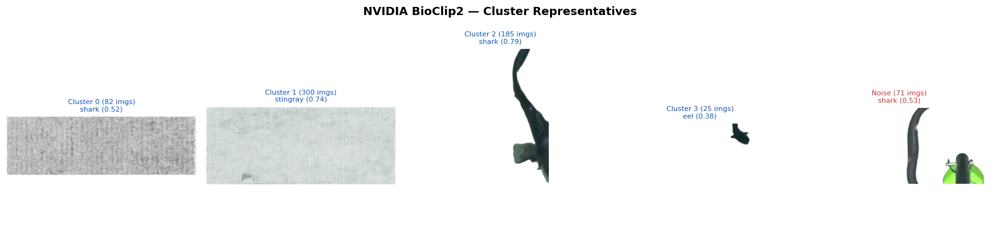

In [41]:
import matplotlib.pyplot as plt
import numpy as np

def cluster_representative_idx(mask):
    """Index of the image closest to the cluster centroid."""
    embs     = image_embeddings[mask]
    centroid = embs.mean(axis=0, keepdims=True)
    local_i  = int(np.argmin(np.linalg.norm(embs - centroid, axis=1)))
    return np.where(mask)[0][local_i]

plot_lbls = [l for l in unique_clusters if l >= 0] + ([-1] if n_noise > 0 else [])
n_cols    = min(6, len(plot_lbls))
n_rows    = max(1, (len(plot_lbls) + n_cols - 1) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 4 * n_rows), squeeze=False)
axes_flat = axes.flatten()

for ax_idx, lbl in enumerate(plot_lbls):
    mask    = cluster_labels == lbl
    rep_idx = cluster_representative_idx(mask)

    axes_flat[ax_idx].imshow(pil_images[rep_idx])

    top1  = predictions_df.iloc[rep_idx]['top1_label']
    score = predictions_df.iloc[rep_idx]['top1_score']
    count = int(mask.sum())

    if lbl == -1:
        title = f'Noise ({count} imgs)\n{top1} ({score:.2f})'
        color = '#cc3333'
    else:
        title = f'Cluster {lbl} ({count} imgs)\n{top1} ({score:.2f})'
        color = '#1155bb'

    axes_flat[ax_idx].set_title(title, fontsize=8, color=color)
    axes_flat[ax_idx].axis('off')

for ax in axes_flat[len(plot_lbls):]:
    ax.axis('off')

plt.suptitle('NVIDIA BioClip2 — Cluster Representatives', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### All images per cluster (thumbnail grid)

Shows every crop in each cluster so you can spot mis-classifications.

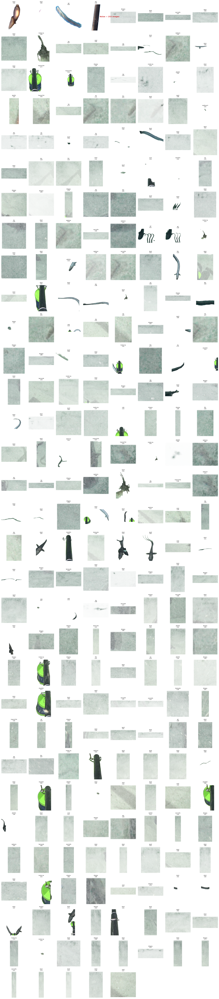

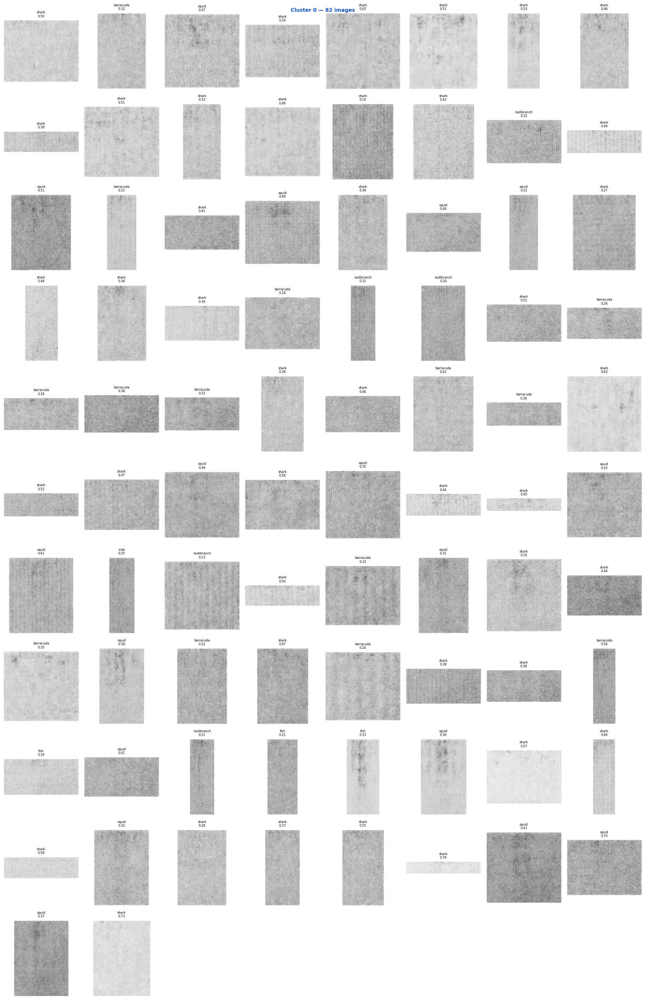

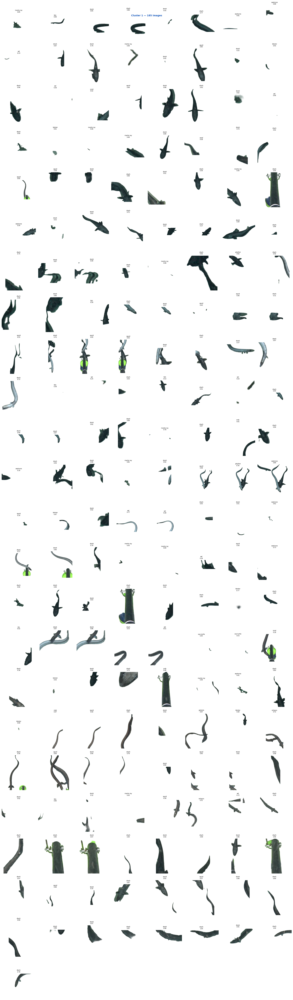

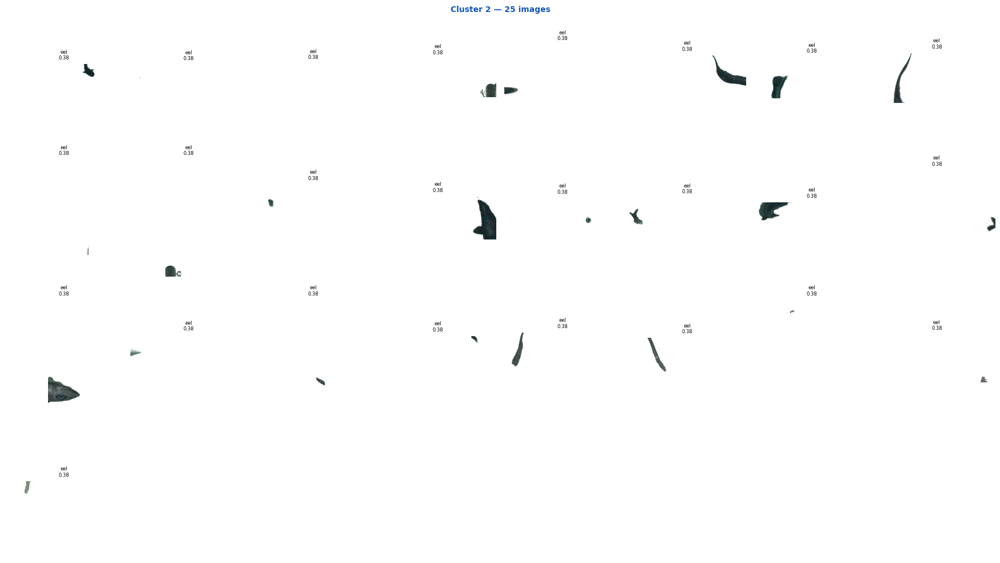

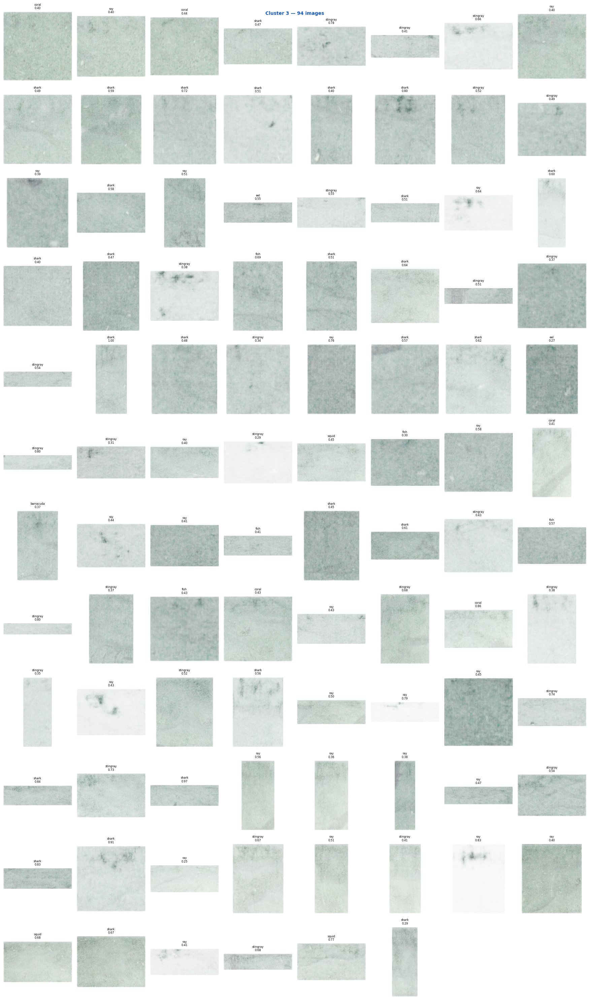

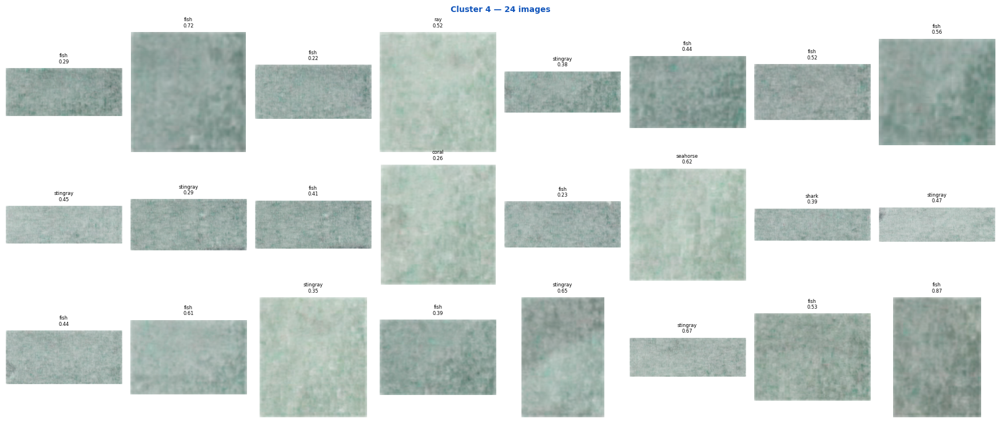

In [37]:
THUMB_COLS = 8   # thumbnails per row

for lbl in unique_clusters:
    mask    = cluster_labels == lbl
    indices = np.where(mask)[0]
    tag     = 'Noise' if lbl == -1 else f'Cluster {lbl}'
    color   = '#cc3333' if lbl == -1 else '#1155bb'

    n_cols  = min(THUMB_COLS, len(indices))
    n_rows  = max(1, (len(indices) + n_cols - 1) // n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.5 * n_rows), squeeze=False)
    axes_flat = axes.flatten()

    for ax_idx, img_idx in enumerate(indices):
        axes_flat[ax_idx].imshow(pil_images[img_idx])
        top1  = predictions_df.iloc[img_idx]['top1_label']
        score = predictions_df.iloc[img_idx]['top1_score']
        axes_flat[ax_idx].set_title(f'{top1}\n{score:.2f}', fontsize=6)
        axes_flat[ax_idx].axis('off')

    for ax in axes_flat[len(indices):]:
        ax.axis('off')

    plt.suptitle(f'{tag} — {len(indices)} images', fontsize=10, fontweight='bold', color=color)
    plt.tight_layout()
    plt.show()

## 11 · Save Results to CSV

In [ ]:
import re

# ── Enrich predictions_df with cluster ID ────────────────────────────────────
predictions_df['cluster_id'] = cluster_labels

col_order = [
    'media_id', 'track_id', 'frame', 'confidence',
    'cluster_id', 'top1_label', 'top1_score',
]
for k in [2, 3]:
    for t in ['label', 'score']:
        col = f'top{k}_{t}'
        if col in predictions_df.columns:
            col_order.append(col)

out_df = predictions_df[[c for c in col_order if c in predictions_df.columns]]

out_csv = os.path.join(OUTPUT_DIR, 'bioclip2_predictions.csv')
out_df.to_csv(out_csv, index=False)
print(f'Saved: {out_csv}')

from IPython.display import display
display(out_df)

## 12 · Summary Stats

In [ ]:
print('=== BioClip2 Run Summary ===')
print(f'Total crops analysed : {len(out_df)}')
print(f'Clusters found       : {n_clusters}')
print(f'Noise/outliers       : {n_noise}')
print()
print('--- Top-1 Species Distribution ---')
print(out_df['top1_label'].value_counts().to_string())
print()
print('--- Detections per video ---')
print(out_df['media_id'].value_counts().to_string())